In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

С помощью pandas загрузите датасет для предсказания цены квартиры, прилагающийся к этой работе.

In [ ]:
df = pd.read_csv('data.csv')

In [ ]:
df

,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
0,11809,27,3.0,115.027311,NaN,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,NaN,0,0,B,305018.871089
1,3013,22,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407
2,8215,1,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.0,3,1,B,282078.720850
3,2352,1,1.0,40.409907,NaN,1.0,10,22.0,1977,0.007122,B,B,1,264,0,NaN,0,1,B,168106.007630
4,13866,94,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,NaN,0,6,B,343995.102962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1260,61,2.0,49.090728,33.272626,6.0,3,12.0,1981,0.300323,B,B,52,10311,6,NaN,1,9,B,119367.455796
9996,16265,27,2.0,64.307684,37.038420,9.0,13,0.0,1977,0.072158,B,B,2,629,1,NaN,0,0,A,199715.148807
9997,2795,178,1.0,29.648057,16.555363,5.0,3,5.0,1958,0.460556,B,B,20,4386,14,NaN,1,5,B,165953.912580
9998,14561,21,1.0,32.330292,22.326870,5.0,3,9.0,1969,0.194489,B,B,47,8004,3,125.0,3,5,B,171842.411855


Выведите на экран несколько первых и несколько последний строк файла.

In [ ]:
df.head(5)

,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
0,11809,27,3.0,115.027311,NaN,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,NaN,0,0,B,305018.871089
1,3013,22,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407
2,8215,1,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.0,3,1,B,282078.720850
3,2352,1,1.0,40.409907,NaN,1.0,10,22.0,1977,0.007122,B,B,1,264,0,NaN,0,1,B,168106.007630
4,13866,94,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,NaN,0,6,B,343995.102962


In [ ]:
df.tail(5)

,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
9995,1260,61,2.0,49.090728,33.272626,6.0,3,12.0,1981,0.300323,B,B,52,10311,6,NaN,1,9,B,119367.455796
9996,16265,27,2.0,64.307684,37.038420,9.0,13,0.0,1977,0.072158,B,B,2,629,1,NaN,0,0,A,199715.148807
9997,2795,178,1.0,29.648057,16.555363,5.0,3,5.0,1958,0.460556,B,B,20,4386,14,NaN,1,5,B,165953.912580
9998,14561,21,1.0,32.330292,22.326870,5.0,3,9.0,1969,0.194489,B,B,47,8004,3,125.0,3,5,B,171842.411855
9999,7202,94,1.0,35.815476,22.301367,6.0,9,9.0,1975,0.127376,B,B,43,8429,3,NaN,3,9,B,177685.627486


Выведите с помощью методов pandas основные количественные параметры датасета: количество строк и столбцов, тип данных каждого поля, количество значений в каждом столбце, шкала измерения каждого численного поля.

In [ ]:
print("Строки:", df.shape[0])
print("Столбцы:", df.shape[1])

Строки: 10000
Столбцы: 20


In [ ]:
df.dtypes

,0
Id,int64
DistrictId,int64
Rooms,float64
Square,float64
LifeSquare,float64
KitchenSquare,float64
Floor,int64
HouseFloor,float64
HouseYear,int64
Ecology_1,float64


In [ ]:
df.count()

,0
Id,10000
DistrictId,10000
Rooms,10000
Square,10000
LifeSquare,7887
KitchenSquare,10000
Floor,10000
HouseFloor,10000
HouseYear,10000
Ecology_1,10000


In [ ]:
# Шкала измерения
num_columns = df.select_dtypes(include=['int64', 'float64']).columns
print("Численные поля и их шкала измерения (напр. непрерывные, дискретные):")
for col in num_columns:
    if len(df[col].unique()) < 20:
        scale = 'дискретная'
    else:
        scale = 'непрерывная'
    print(f"{col}: {scale}")

Численные поля и их шкала измерения (напр. непрерывные, дискретные):
Id: непрерывная
DistrictId: непрерывная
Rooms: дискретная
Square: непрерывная
LifeSquare: непрерывная
KitchenSquare: непрерывная
Floor: непрерывная
HouseFloor: непрерывная
HouseYear: непрерывная
Ecology_1: непрерывная
Social_1: непрерывная
Social_2: непрерывная
Social_3: непрерывная
Healthcare_1: непрерывная
Helthcare_2: дискретная
Shops_1: дискретная
Price: непрерывная


Удалите из таблицы столбцы, содержащие идентификаторы, переименуйте все оставшиеся названия колонок на русском языке.

In [ ]:
df.drop('Id', axis = 1, inplace = True)
df.drop('DistrictId', axis = 1, inplace = True)

In [ ]:
df.columns = ['Комнаты', "Площадь", "Площадь гостинной", "Площадь кухни", "Этаж", "Этажей в доме", "Год постройки", "Экология 1", "Экология 2", "Экология 3", "Социальный коэффициент 1", "Социальный коэффициент 2", "Социальный коэффициент 3", "Здравохранение 1", "Здравохранения 2", "Магазин 1", "Магазин 2", "Цена"]

In [ ]:
df

,Комнаты,Площадь,Площадь гостинной,Площадь кухни,Этаж,Этажей в доме,Год постройки,Экология 1,Экология 2,Экология 3,Социальный коэффициент 1,Социальный коэффициент 2,Социальный коэффициент 3,Здравохранение 1,Здравохранения 2,Магазин 1,Магазин 2,Цена
0,3.0,115.027311,NaN,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,NaN,0,0,B,305018.871089
1,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407
2,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.0,3,1,B,282078.720850
3,1.0,40.409907,NaN,1.0,10,22.0,1977,0.007122,B,B,1,264,0,NaN,0,1,B,168106.007630
4,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,NaN,0,6,B,343995.102962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2.0,49.090728,33.272626,6.0,3,12.0,1981,0.300323,B,B,52,10311,6,NaN,1,9,B,119367.455796
9996,2.0,64.307684,37.038420,9.0,13,0.0,1977,0.072158,B,B,2,629,1,NaN,0,0,A,199715.148807
9997,1.0,29.648057,16.555363,5.0,3,5.0,1958,0.460556,B,B,20,4386,14,NaN,1,5,B,165953.912580
9998,1.0,32.330292,22.326870,5.0,3,9.0,1969,0.194489,B,B,47,8004,3,125.0,3,5,B,171842.411855


Выведите отдельно столбец, содержащий цену, по номеру и названию. Выведите первую, десятую и предпоследнюю строку таблицы по номеру и по индексу.

In [ ]:
df['Цена']

,Цена
0,305018.871089
1,177734.553407
2,282078.720850
3,168106.007630
4,343995.102962
...,...
9995,119367.455796
9996,199715.148807
9997,165953.912580
9998,171842.411855


In [ ]:
df[df.columns[17]]

,Цена
0,305018.871089
1,177734.553407
2,282078.720850
3,168106.007630
4,343995.102962
...,...
9995,119367.455796
9996,199715.148807
9997,165953.912580
9998,171842.411855


In [ ]:
df.iloc[[1]]

,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
1,3013,22,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407


In [ ]:
df.iloc[[10]]

,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
10,535,2,3.0,74.199049,44.735889,10.0,5,14.0,2008,0.035145,B,B,42,9292,3,2620.0,0,3,B,512797.373401


In [ ]:
df.iloc[[-1]]

,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
9999,7202,94,1.0,35.815476,22.301367,6.0,9,9.0,1975,0.127376,B,B,43,8429,3,NaN,3,9,B,177685.627486


Выделите в отдельную таблицу последние десять строк. Уберите в ней столбец с ценой. Склейте ее с первоначальной таблицей при помощи append. Заполните отсутствующие значения цены средним по таблице.

In [ ]:
df2 = df.loc[9990:10000]

In [ ]:
df2

,Комнаты,Площадь,Площадь гостинной,Площадь кухни,Этаж,Этажей в доме,Год постройки,Экология 1,Экология 2,Экология 3,Социальный коэффициент 1,Социальный коэффициент 2,Социальный коэффициент 3,Здравохранение 1,Здравохранения 2,Магазин 1,Магазин 2,Цена
9990,1.0,18.983962,11.419796,2.0,1,5.0,1967,0.194489,B,B,47,8004,3,125.0,3,5,B,112411.221700
9991,2.0,62.648779,NaN,0.0,6,17.0,1977,0.243205,B,B,5,1564,0,540.0,0,0,B,182625.548872
9992,2.0,50.902724,27.159548,6.0,4,9.0,1972,0.127812,B,B,28,7287,5,320.0,1,3,B,196641.468817
9993,3.0,84.486078,88.931509,0.0,4,22.0,2016,0.007122,B,B,1,264,0,NaN,0,1,B,264213.558631
9994,1.0,43.303458,21.519087,8.0,12,14.0,1992,0.161532,B,B,25,5648,1,30.0,2,4,B,136744.340827
9995,2.0,49.090728,33.272626,6.0,3,12.0,1981,0.300323,B,B,52,10311,6,NaN,1,9,B,119367.455796
9996,2.0,64.307684,37.038420,9.0,13,0.0,1977,0.072158,B,B,2,629,1,NaN,0,0,A,199715.148807
9997,1.0,29.648057,16.555363,5.0,3,5.0,1958,0.460556,B,B,20,4386,14,NaN,1,5,B,165953.912580
9998,1.0,32.330292,22.326870,5.0,3,9.0,1969,0.194489,B,B,47,8004,3,125.0,3,5,B,171842.411855
9999,1.0,35.815476,22.301367,6.0,9,9.0,1975,0.127376,B,B,43,8429,3,NaN,3,9,B,177685.627486


In [ ]:
df2.drop('Цена', axis=1, inplace=True)

<ipython-input-48-1a43a61b26a9>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2.drop('Цена', axis=1, inplace=True)


In [ ]:
df3 = pd.concat([df, df2])

In [ ]:
df3

,Комнаты,Площадь,Площадь гостинной,Площадь кухни,Этаж,Этажей в доме,Год постройки,Экология 1,Экология 2,Экология 3,Социальный коэффициент 1,Социальный коэффициент 2,Социальный коэффициент 3,Здравохранение 1,Здравохранения 2,Магазин 1,Магазин 2,Цена
0,3.0,115.027311,NaN,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,NaN,0,0,B,305018.871089
1,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407
2,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.0,3,1,B,282078.720850
3,1.0,40.409907,NaN,1.0,10,22.0,1977,0.007122,B,B,1,264,0,NaN,0,1,B,168106.007630
4,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,NaN,0,6,B,343995.102962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2.0,49.090728,33.272626,6.0,3,12.0,1981,0.300323,B,B,52,10311,6,NaN,1,9,B,NaN
9996,2.0,64.307684,37.038420,9.0,13,0.0,1977,0.072158,B,B,2,629,1,NaN,0,0,A,NaN
9997,1.0,29.648057,16.555363,5.0,3,5.0,1958,0.460556,B,B,20,4386,14,NaN,1,5,B,NaN
9998,1.0,32.330292,22.326870,5.0,3,9.0,1969,0.194489,B,B,47,8004,3,125.0,3,5,B,NaN


In [ ]:
df3['Площадь гостинной'].mean(axis=0)

37.19277144667999

In [ ]:
df3.loc[(df3['Площадь гостинной'] == 'NaN'), ['Площадь гостинной']] = 111

In [ ]:
df3['Площадь гостинной'].fillna(df3['Площадь гостинной'].mean(), inplace=True)
df3['Здравохранение 1'].fillna(df3['Здравохранение 1'].mean(), inplace=True)
df3['Цена'].fillna(df3['Цена'].mean(), inplace=True)

In [ ]:
df3

,Комнаты,Площадь,Площадь гостинной,Площадь кухни,Этаж,Этажей в доме,Год постройки,Экология 1,Экология 2,Экология 3,Социальный коэффициент 1,Социальный коэффициент 2,Социальный коэффициент 3,Здравохранение 1,Здравохранения 2,Магазин 1,Магазин 2,Цена
0,3.0,115.027311,37.192771,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,1142.025927,0,0,B,305018.871089
1,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.000000,1,0,B,177734.553407
2,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.000000,3,1,B,282078.720850
3,1.0,40.409907,37.192771,1.0,10,22.0,1977,0.007122,B,B,1,264,0,1142.025927,0,1,B,168106.007630
4,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,1142.025927,0,6,B,343995.102962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2.0,49.090728,33.272626,6.0,3,12.0,1981,0.300323,B,B,52,10311,6,1142.025927,1,9,B,214138.857399
9996,2.0,64.307684,37.038420,9.0,13,0.0,1977,0.072158,B,B,2,629,1,1142.025927,0,0,A,214138.857399
9997,1.0,29.648057,16.555363,5.0,3,5.0,1958,0.460556,B,B,20,4386,14,1142.025927,1,5,B,214138.857399
9998,1.0,32.330292,22.326870,5.0,3,9.0,1969,0.194489,B,B,47,8004,3,125.000000,3,5,B,214138.857399


Выделите пять последних колонок в отдельную таблицу. Удалите в ней строки, в которых цена ниже среднего. Присоедините эту таблицу к изначальной (выберите самый подходящий тип соединения).

In [ ]:
df4 = df3.iloc[:, [-5, -4, -3, -2, -1]]

In [ ]:
df4 = df4[df4['Цена'] < df4['Цена'].mean()]

In [ ]:
df4

,Здравохранение 1,Здравохранения 2,Магазин 1,Магазин 2,Цена
1,1183.000000,1,0,B,177734.553407
3,1142.025927,0,1,B,168106.007630
5,2078.000000,2,4,B,161044.944138
6,80.000000,0,3,B,142402.739272
8,1142.025927,0,1,B,160400.401732
...,...,...,...,...,...
9995,1142.025927,1,9,B,119367.455796
9996,1142.025927,0,0,A,199715.148807
9997,1142.025927,1,5,B,165953.912580
9998,125.000000,3,5,B,171842.411855


In [ ]:
df5 = pd.concat([df, df4])

In [ ]:
df5

,Комнаты,Площадь,Площадь гостинной,Площадь кухни,Этаж,Этажей в доме,Год постройки,Экология 1,Экология 2,Экология 3,Социальный коэффициент 1,Социальный коэффициент 2,Социальный коэффициент 3,Здравохранение 1,Здравохранения 2,Магазин 1,Магазин 2,Цена
0,3.0,115.027311,37.192771,10.0,4.0,10.0,2014.0,0.075424,B,B,11.0,3097.0,0.0,1142.025927,0,0,B,305018.871089
1,1.0,39.832524,23.169223,8.0,7.0,8.0,1966.0,0.118537,B,B,30.0,6207.0,1.0,1183.000000,1,0,B,177734.553407
2,3.0,78.342215,47.671972,10.0,2.0,17.0,1988.0,0.025609,B,B,33.0,5261.0,0.0,240.000000,3,1,B,282078.720850
3,1.0,40.409907,37.192771,1.0,10.0,22.0,1977.0,0.007122,B,B,1.0,264.0,0.0,1142.025927,0,1,B,168106.007630
4,2.0,64.285067,38.562517,9.0,16.0,16.0,1972.0,0.282798,B,B,33.0,8667.0,2.0,1142.025927,0,6,B,343995.102962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1142.025927,1,9,B,119367.455796
9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1142.025927,0,0,A,199715.148807
9997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1142.025927,1,5,B,165953.912580
9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,125.000000,3,5,B,171842.411855


Выведите таблицу, содержащую среднюю цену и количество квартир на каждом этаже из первоначального набора данных.

In [ ]:
df

,Комнаты,Площадь,Площадь гостинной,Площадь кухни,Этаж,Этажей в доме,Год постройки,Экология 1,Экология 2,Экология 3,Социальный коэффициент 1,Социальный коэффициент 2,Социальный коэффициент 3,Здравохранение 1,Здравохранения 2,Магазин 1,Магазин 2,Цена
0,3.0,115.027311,NaN,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,NaN,0,0,B,305018.871089
1,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407
2,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.0,3,1,B,282078.720850
3,1.0,40.409907,NaN,1.0,10,22.0,1977,0.007122,B,B,1,264,0,NaN,0,1,B,168106.007630
4,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,NaN,0,6,B,343995.102962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2.0,49.090728,33.272626,6.0,3,12.0,1981,0.300323,B,B,52,10311,6,NaN,1,9,B,119367.455796
9996,2.0,64.307684,37.038420,9.0,13,0.0,1977,0.072158,B,B,2,629,1,NaN,0,0,A,199715.148807
9997,1.0,29.648057,16.555363,5.0,3,5.0,1958,0.460556,B,B,20,4386,14,NaN,1,5,B,165953.912580
9998,1.0,32.330292,22.326870,5.0,3,9.0,1969,0.194489,B,B,47,8004,3,125.0,3,5,B,171842.411855


In [ ]:
df6 = df['Этаж']*df['Этажей в доме']

In [ ]:
# a1 = df6.sum(axis=0)
a1 = df['Этаж']

In [ ]:
a1

,Этаж
0,4
1,7
2,2
3,10
4,16
...,...
9995,3
9996,13
9997,3
9998,3


In [ ]:
table = pd.DataFrame(columns=['Ср знач цены'])
table.loc[len(table.index )] = df['Цена'].mean()

In [ ]:
table

,Ср знач цены
0,214138.857399


In [ ]:
a = pd.concat([a1, table])

In [ ]:
a

,0,Ср знач цены
0,4.0,NaN
1,7.0,NaN
2,2.0,NaN
3,10.0,NaN
4,16.0,NaN
...,...,...
9996,13.0,NaN
9997,3.0,NaN
9998,3.0,NaN
9999,9.0,NaN


Сохраните получившуюся таблицу в файлы формата csv и xlsx. Прочитайте их и убедитесь, что данные отображаются корректно.

In [ ]:
a.to_csv('file1.csv')

In [ ]:
a.to_excel('file1.xlsx')

Создайте в Excel или другом табличном редакторе таблицу, содержащую несколько численных и текстовых полей. Прочитайте ее в программу при помощи pandas.

In [ ]:
tab = pd.read_excel('Name.xlsx')

In [ ]:
tab

,Unnamed: 0,Name,Surname
0,0,Stacy,Smith
1,1,Bloom,White
2,2,Bob,Sinclar


In [ ]:
df

,Комнаты,Площадь,Площадь гостинной,Площадь кухни,Этаж,Этажей в доме,Год постройки,Экология 1,Экология 2,Экология 3,Социальный коэффициент 1,Социальный коэффициент 2,Социальный коэффициент 3,Здравохранение 1,Здравохранения 2,Магазин 1,Магазин 2,Цена
0,3.0,115.027311,NaN,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,NaN,0,0,B,305018.871089
1,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407
2,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.0,3,1,B,282078.720850
3,1.0,40.409907,NaN,1.0,10,22.0,1977,0.007122,B,B,1,264,0,NaN,0,1,B,168106.007630
4,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,NaN,0,6,B,343995.102962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2.0,49.090728,33.272626,6.0,3,12.0,1981,0.300323,B,B,52,10311,6,NaN,1,9,B,119367.455796
9996,2.0,64.307684,37.038420,9.0,13,0.0,1977,0.072158,B,B,2,629,1,NaN,0,0,A,199715.148807
9997,1.0,29.648057,16.555363,5.0,3,5.0,1958,0.460556,B,B,20,4386,14,NaN,1,5,B,165953.912580
9998,1.0,32.330292,22.326870,5.0,3,9.0,1969,0.194489,B,B,47,8004,3,125.0,3,5,B,171842.411855


Постройте круговую диаграмму для признака Rooms, иллюстрирующую количество квартир в процентах в зависимости от количества комнат. Сделайте сектор с наибольшим числом квартир выдвинутым.

In [ ]:
rooms = pd.concat([df['Комнаты'], df["Этажей в доме"]], axis=1)

In [ ]:
rooms

,Комнаты,Этажей в доме
0,3.0,10.0
1,1.0,8.0
2,3.0,17.0
3,1.0,22.0
4,2.0,16.0
...,...,...
9995,2.0,12.0
9996,2.0,0.0
9997,1.0,5.0
9998,1.0,9.0


In [ ]:
df['Комнаты'].sum(axis=0)

18905.0

In [ ]:
df['Этаж'].sum(axis=0)

85267

array([<Axes: ylabel='Этажей в доме'>], dtype=object)

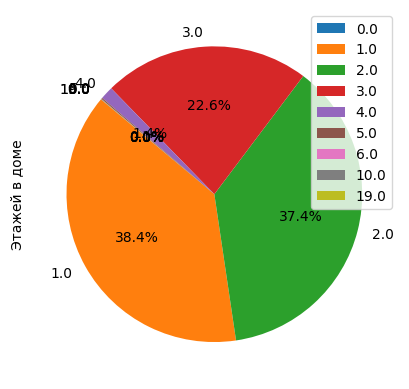

In [ ]:
df_grouped = rooms.groupby('Комнаты').sum()
df_grouped['Этажей в доме'] = df_grouped['Этажей в доме'].astype(float)
# explode = (1, 0, 0, 0, 0)

df_grouped.plot(kind='pie', autopct='%1.1f%%', startangle=140, subplots=True)


Постройте гистограмму по целевой переменной Price. Оцените визуально, по какой цене продаётся наибольшее количество квартир.

array([[<Axes: title={'center': 'Цена'}>]], dtype=object)

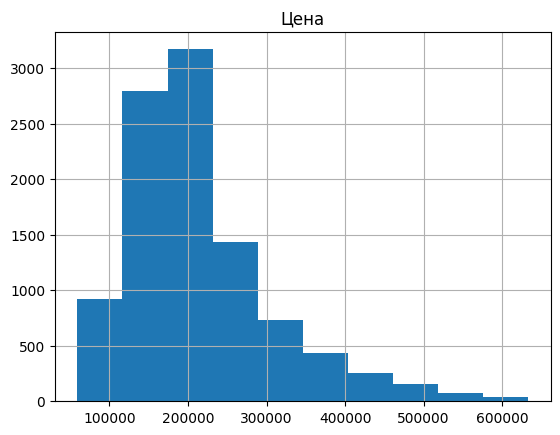

In [ ]:
df.hist(column='Цена')

Постройте диаграммы рассеяния для признаков Rooms, Square, HouseFloor, HouseYear в зависимости от целевой переменной Price в одной области figure. Оцените визуально, есть ли среди них такие, на которых разброс точек близок к линейной функции.

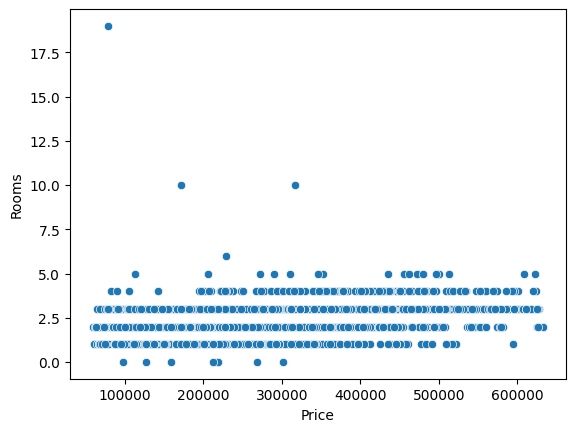

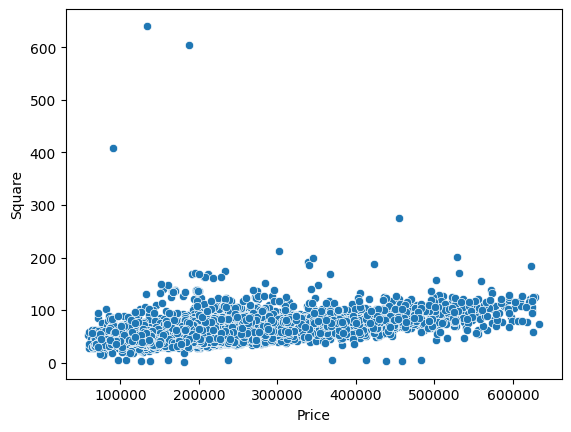

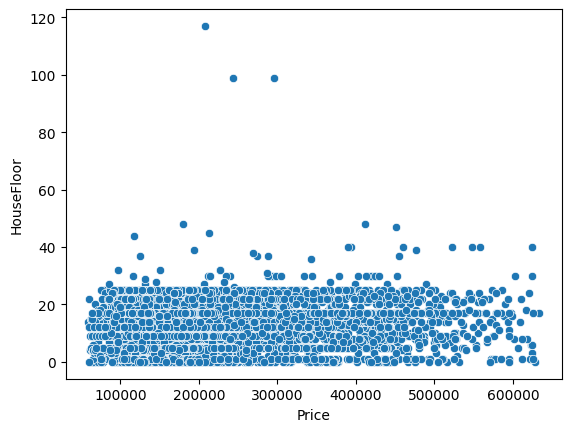

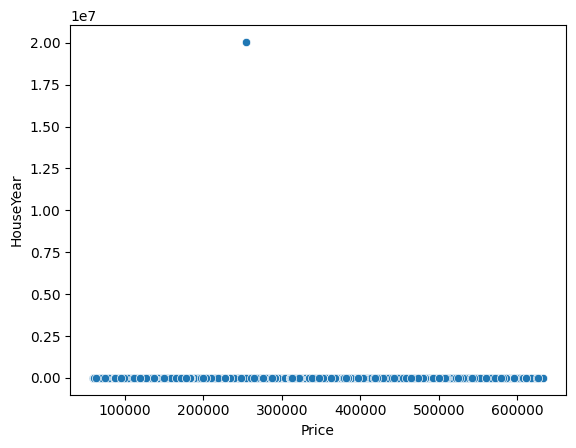

In [ ]:
for i in ['Rooms', 'Square', 'HouseFloor', 'HouseYear']:
    sns.scatterplot(data=df[['Rooms', 'Square', 'HouseFloor', 'HouseYear', 'Price']], x=df.Price, y=df[i])
    plt.show()


Постройте ядерную оценку плотности целевой переменной Price. Оцените визуально, напоминает ли полученный график нормальное распределение. Постройте двумерную ядерную оценку плотности для целевой переменной Price и признака HouseFloor, затем оцените визуально на каких этажах и по какой цене продаётся основная масса квартир.

<Axes: xlabel='Price', ylabel='Density'>

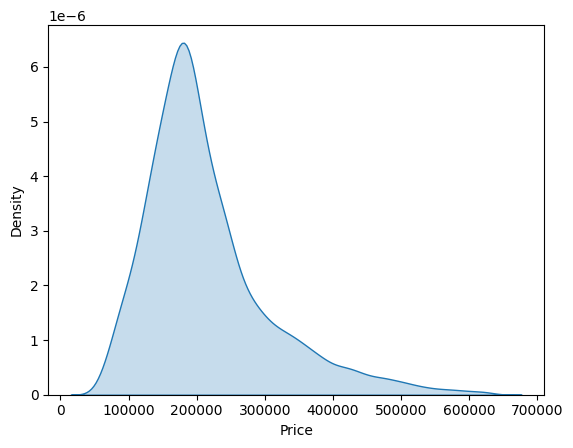

In [ ]:
sns.kdeplot(df.Price, fill=True)

<Axes: xlabel='Price', ylabel='HouseFloor'>

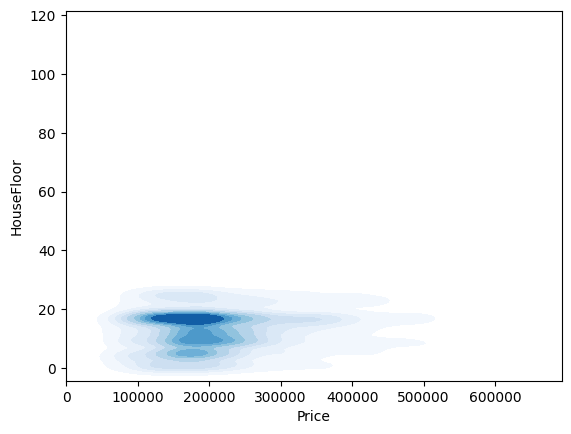

In [ ]:
sns.kdeplot(x=df.Price, y=df.HouseFloor, fill=True, cmap='Blues')

Постройте ящиковую диаграмму признака Square. Оцените визуально имеются ли выбросы, и, если да, то начиная с какого размера площади значение признака можно считать выбросом.

<Axes: >

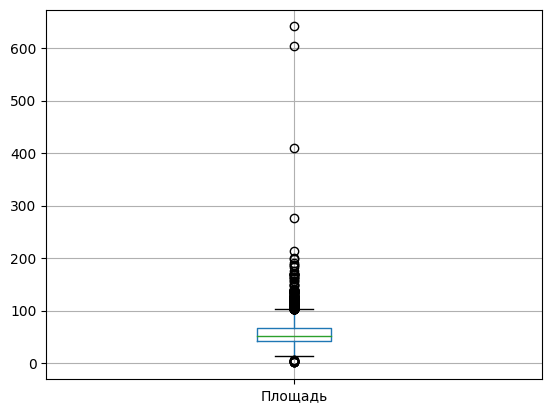

In [ ]:
df.boxplot(column='Площадь')

При помощи сетки графиков PairGrid визуализируйте попарные отношения признаков Rooms, Square, HouseFloor, HouseYear, Price следующим образом: на диагонали - гистограммы, под диагональю - ядерные оценки плотности, над диагональю - диаграммы рассеяния. По результатам визуализации сделайте выводы.

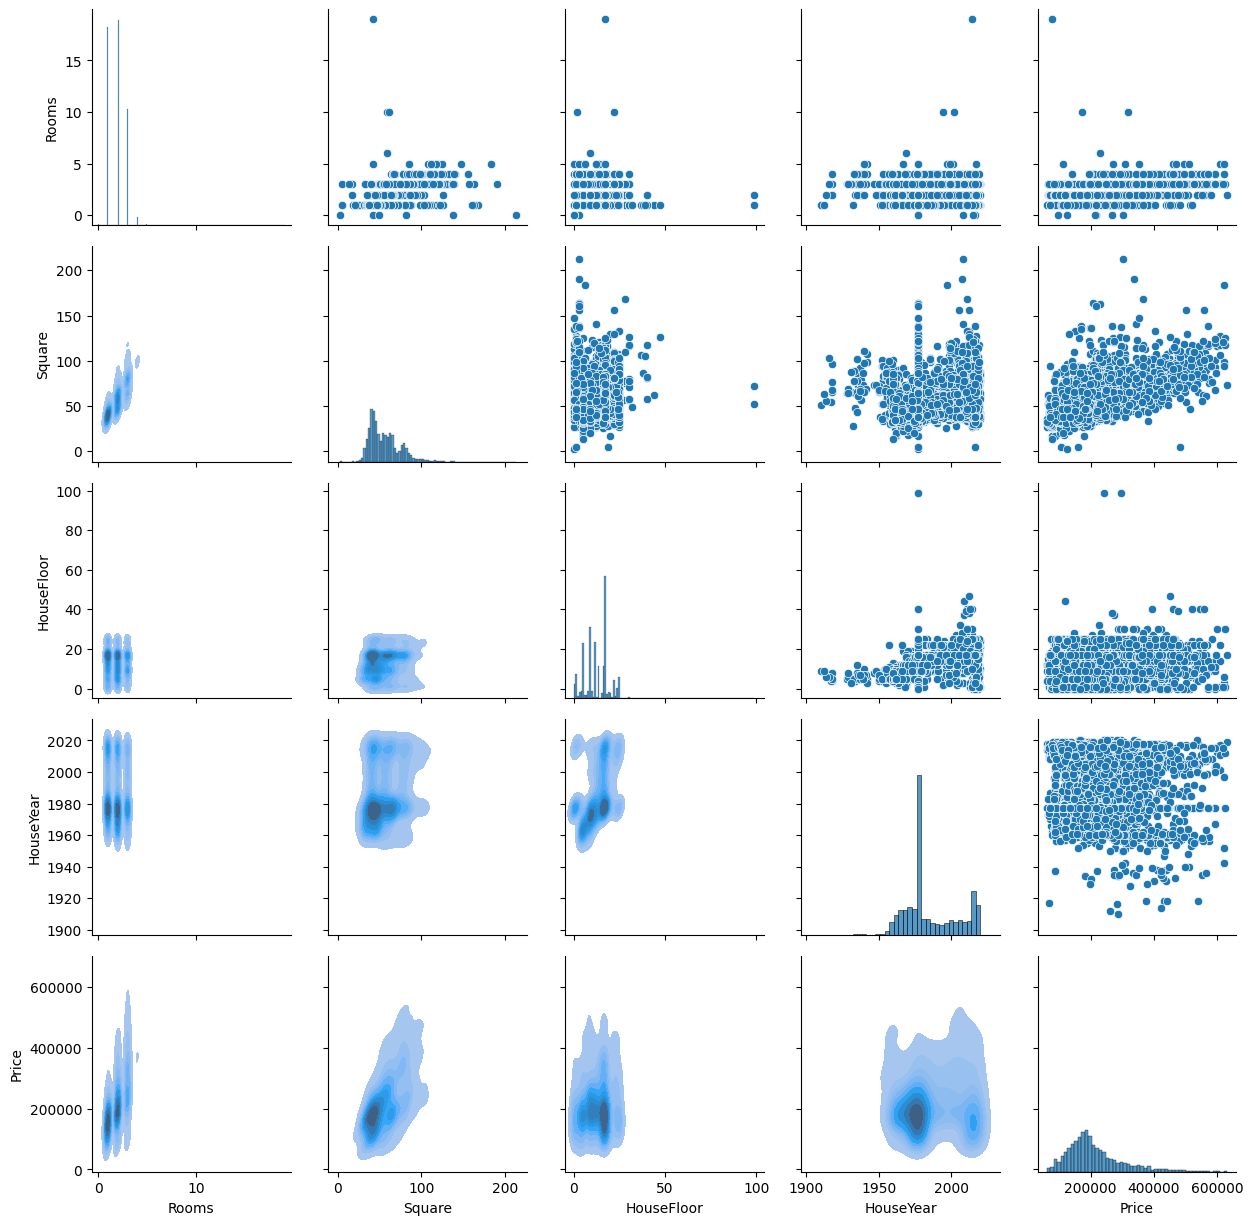

In [ ]:
df1 = df[['Rooms', 'Square', 'HouseFloor', 'HouseYear', 'Price']].sample(5000, random_state=42)
g = sns.PairGrid(df1)
g.map_diag(sns.histplot, kde=False)
g.map_lower(sns.kdeplot, fill=True)
g.map_upper(sns.scatterplot)
plt.show()

In [ ]:
df.head()

,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
0,11809,27,3.0,115.027311,NaN,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,NaN,0,0,B,305018.871089
1,3013,22,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407
2,8215,1,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.0,3,1,B,282078.720850
3,2352,1,1.0,40.409907,NaN,1.0,10,22.0,1977,0.007122,B,B,1,264,0,NaN,0,1,B,168106.007630
4,13866,94,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,NaN,0,6,B,343995.102962


Постройте тепловую карту матрицы корреляции (df.corr()) признаков Rooms, Square, HouseFloor, HouseYear, Price. По ней определите, какие признаки являются зависимыми (у таких признаков коэффициент корреляции близок к единице).

<Axes: >

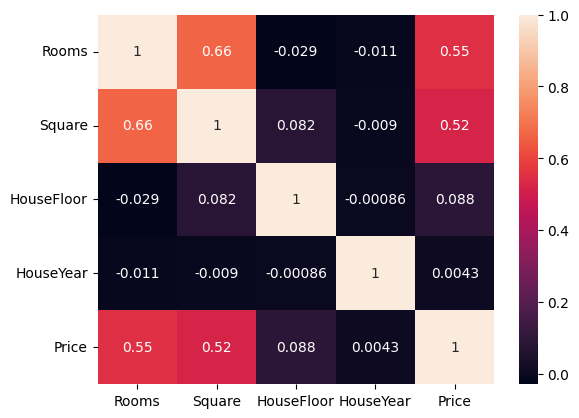

In [ ]:
sns.heatmap(df[['Rooms', 'Square', 'HouseFloor', 'HouseYear', 'Price']].corr(), annot=True)